In [1]:
!pip install pennylane torch torchvision matplotlib scikit-learn
!pip install medmnist

  Using cached pennylane-0.45.1-py3-none-any.whl.metadata (10 kB)
     ---------------------------------------- 0.0/80.3 kB ? eta -:--:--
     ---------------------------------------- 0.0/80.3 kB ? eta -:--:--
     ----- ---------------------------------- 10.2/80.3 kB ? eta -:--:--
     ------------------------------ --------- 61.4/80.3 kB 1.1 MB/s eta 0:00:01
     -------------------------------------- 80.3/80.3 kB 560.2 kB/s eta 0:00:00
     ---------------------------------------- 0.0/61.0 kB ? eta -:--:--
     ------------------------- ------------ 41.0/61.0 kB 991.0 kB/s eta 0:00:01
     ------------------------- ------------ 41.0/61.0 kB 991.0 kB/s eta 0:00:01
     ------------------------------- ------ 51.2/61.0 kB 375.8 kB/s eta 0:00:01
     -------------------------------------- 61.0/61.0 kB 325.1 kB/s eta 0:00:00
  Using cached networkx-3.6.1-py3-none-any.whl.metadata (6.8 kB)
  Using cached rustworkx-0.18.1-cp310-abi3-win_amd64.whl.metadata (10 kB)
  Using cached autograd-1.


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached medmnist-3.0.2-py3-none-any.whl.metadata (14 kB)
  Using cached scikit_image-0.26.0-cp311-cp311-win_amd64.whl.metadata (15 kB)
     ---------------------------------------- 0.0/57.4 kB ? eta -:--:--
     ------- -------------------------------- 10.2/57.4 kB ? eta -:--:--
     ---------------------------------------- 57.4/57.4 kB 1.0 MB/s eta 0:00:00
  Using cached fire-0.7.1-py3-none-any.whl.metadata (5.8 kB)
  Using cached tifffile-2026.3.3-py3-none-any.whl.metadata (31 kB)
Using cached medmnist-3.0.2-py3-none-any.whl (25 kB)
Using cached fire-0.7.1-py3-none-any.whl (115 kB)
   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   ---------------------------------------- 0.1/9.9 MB 3.3 MB/s eta 0:00:03
   - -------------------------------------- 0.4/9.9 MB 5.5 MB/s eta 0:00:02
   --- ------------------------------------ 0.8/9.9 MB 5.8 MB/s eta 0:00:02
   ----- ---------------------------------- 1.2/9.9 MB 7.2 MB/s eta 0:00:02
   ------- ------------------


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import torch
from torch.utils.data import DataLoader, TensorDataset
from torchvision import transforms
from medmnist import PneumoniaMNIST

# Transform grayscale (1 channel) to 3-channel RGB and resize for ResNet-18
data_transform = transforms.Compose([
    transforms.Lambda(lambda img: img.convert('RGB')),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Download and load official PneumoniaMNIST splits
train_raw = PneumoniaMNIST(split='train', transform=data_transform, download=True)
val_raw   = PneumoniaMNIST(split='val',   transform=data_transform, download=True)
test_raw  = PneumoniaMNIST(split='test',  transform=data_transform, download=True)

print(f"Dataset loaded: {len(train_raw)} train, {len(val_raw)} val, {len(test_raw)} test images.")

100%|██████████| 4.17M/4.17M [00:14<00:00, 296kB/s] 

Dataset loaded: 4708 train, 524 val, 624 test images.


In [3]:
from torchvision import models
import torch.nn as nn
from tqdm import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load pre-trained ResNet-18 and strip the final classification head
resnet = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
feature_extractor = nn.Sequential(*list(resnet.children())[:-1]).to(device)
feature_extractor.eval()

def extract_features(dataset, batch_size=64):
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)
    all_features = []
    all_labels = []

    with torch.no_grad():
        for imgs, lbls in tqdm(loader, desc="Extracting Features"):
            imgs = imgs.to(device)
            feats = feature_extractor(imgs)          # Shape: (B, 512, 1, 1)
            feats = torch.flatten(feats, 1)          # Shape: (B, 512)
            all_features.append(feats.cpu())
            all_labels.append(lbls.squeeze().long()) # Shape: (B,)

    return torch.cat(all_features), torch.cat(all_labels)

# Extract and create fast TensorDataLoaders
X_train, y_train = extract_features(train_raw)
X_val,   y_val   = extract_features(val_raw)
X_test,  y_test  = extract_features(test_raw)

batch_size = 32
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(TensorDataset(X_val, y_val), batch_size=batch_size, shuffle=False)
test_loader  = DataLoader(TensorDataset(X_test, y_test), batch_size=batch_size, shuffle=False)

dataloaders = {'train': train_loader, 'val': val_loader, 'test': test_loader}
print(f"Extracted feature shape: {X_train.shape}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\prath/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:07<00:00, 6.40MB/s]
Extracting Features: 100%|██████████| 10/10 [00:19<00:00,  1.94s/it]

Extracted feature shape: torch.Size([4708, 512])


In [4]:
import copy
import torch.optim as optim

def train_and_evaluate(model, dataloaders, epochs=15, lr=1e-3):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    best_acc = 0.0
    best_weights = copy.deepcopy(model.state_dict())
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    for epoch in range(epochs):
        for phase in ['train', 'val']:
            model.train() if phase == 'train' else model.eval()
            total_loss, correct, total = 0.0, 0, 0

            for feats, labels in dataloaders[phase]:
                feats, labels = feats.to(device), labels.to(device)
                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(feats)
                    loss = criterion(outputs, labels)
                    _, preds = torch.max(outputs, 1)

                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                total_loss += loss.item() * feats.size(0)
                correct += torch.sum(preds == labels).item()
                total += labels.size(0)

            epoch_loss = total_loss / total
            epoch_acc = correct / total
            history[f'{phase}_loss'].append(epoch_loss)
            history[f'{phase}_acc'].append(epoch_acc)

            if phase == 'val' and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_weights = copy.deepcopy(model.state_dict())

        print(f"Epoch {epoch+1:02d}/{epochs:02d} | Train Acc: {history['train_acc'][-1]:.4f} | Val Acc: {history['val_acc'][-1]:.4f}")

    model.load_state_dict(best_weights)
    return model, history

In [5]:
class BottleneckClassicalClassifier(nn.Module):
    def __init__(self, in_features=512, hidden_dim=4, num_classes=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, num_classes)
        )

    def forward(self, x):
        return self.net(x)

classical_model = BottleneckClassicalClassifier().to(device)
print("Training Classical Baseline Model...")
classical_model, classical_history = train_and_evaluate(classical_model, dataloaders, epochs=15, lr=1e-3)

Training Classical Baseline Model...
Epoch 01/15 | Train Acc: 0.7379 | Val Acc: 0.7424
Epoch 02/15 | Train Acc: 0.7421 | Val Acc: 0.7424
Epoch 03/15 | Train Acc: 0.9072 | Val Acc: 0.9179
Epoch 04/15 | Train Acc: 0.9382 | Val Acc: 0.9198
Epoch 05/15 | Train Acc: 0.9416 | Val Acc: 0.9351
Epoch 06/15 | Train Acc: 0.9503 | Val Acc: 0.9427
Epoch 07/15 | Train Acc: 0.9552 | Val Acc: 0.9542
Epoch 08/15 | Train Acc: 0.9552 | Val Acc: 0.9485
Epoch 09/15 | Train Acc: 0.9588 | Val Acc: 0.9523
Epoch 10/15 | Train Acc: 0.9594 | Val Acc: 0.9561
Epoch 11/15 | Train Acc: 0.9596 | Val Acc: 0.9561
Epoch 12/15 | Train Acc: 0.9622 | Val Acc: 0.9561
Epoch 13/15 | Train Acc: 0.9626 | Val Acc: 0.9580
Epoch 14/15 | Train Acc: 0.9605 | Val Acc: 0.9561
Epoch 15/15 | Train Acc: 0.9656 | Val Acc: 0.9542


In [6]:
import pennylane as qml
import numpy as np
import torch
import torch.nn as nn

n_qubits = 4
q_depth = 2
dev = qml.device("default.qubit", wires=n_qubits)

@qml.qnode(dev, interface="torch", diff_method="backprop")
def quantum_circuit(inputs, weights):
    # AngleEmbedding natively supports batched inputs (batch_size, n_qubits)
    qml.AngleEmbedding(inputs, wires=range(n_qubits), rotation="Y")

    # Variational layers: single-qubit rotations followed by entangling CNOTs
    for l in range(q_depth):
        for i in range(n_qubits):
            qml.Rot(weights[l, i, 0], weights[l, i, 1], weights[l, i, 2], wires=i)
        for i in range(n_qubits):
            qml.CNOT(wires=[i, (i + 1) % n_qubits])

    # Measure Pauli-Z expectation values across all 4 qubits
    return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

weight_shapes = {"weights": (q_depth, n_qubits, 3)}
qlayer = qml.qnn.TorchLayer(quantum_circuit, weight_shapes)

class HybridQuantumClassifier(nn.Module):
    def __init__(self, in_features=512, num_classes=2):
        super().__init__()
        self.pre_net = nn.Sequential(
            nn.Linear(in_features, n_qubits),
            nn.Tanh()
        )
        self.qlayer = qlayer
        self.post_net = nn.Linear(n_qubits, num_classes)

    def forward(self, x):
        # Scale tanh outputs into [-pi/2, pi/2]
        x = self.pre_net(x) * (np.pi / 2.0)

        # TorchLayer automatically broadcasts over batch dimension
        x = self.qlayer(x)

        # Ensure tensor matches post_net's device and dtype
        x = x.to(device=self.post_net.weight.device, dtype=torch.float32)
        x = self.post_net(x)
        return x

# Sample 4-element dummy input and matching weight shape
dummy_inputs = torch.zeros(4)
dummy_weights = torch.zeros((q_depth, n_qubits, 3))

# Print standard ASCII diagram
print(qml.draw(quantum_circuit)(dummy_inputs, dummy_weights))

hybrid_model = HybridQuantumClassifier().to(device)
print("Training Hybrid Quantum Model...")
hybrid_model, quantum_history = train_and_evaluate(hybrid_model, dataloaders, epochs=15, lr=5e-3)

0: ─╭AngleEmbedding(M0)──Rot(0.00,0.00,0.00)─╭●───────╭X──Rot(0.00,0.00,0.00)─╭●───────╭X─┤  <Z>
1: ─├AngleEmbedding(M0)──Rot(0.00,0.00,0.00)─╰X─╭●────│───Rot(0.00,0.00,0.00)─╰X─╭●────│──┤  <Z>
2: ─├AngleEmbedding(M0)──Rot(0.00,0.00,0.00)────╰X─╭●─│───Rot(0.00,0.00,0.00)────╰X─╭●─│──┤  <Z>
3: ─╰AngleEmbedding(M0)──Rot(0.00,0.00,0.00)───────╰X─╰●──Rot(0.00,0.00,0.00)───────╰X─╰●─┤  <Z>

M0 = 
tensor([0., 0., 0., 0.])
Training Hybrid Quantum Model...
Epoch 01/15 | Train Acc: 0.7766 | Val Acc: 0.9256
Epoch 02/15 | Train Acc: 0.9382 | Val Acc: 0.9542
Epoch 03/15 | Train Acc: 0.9427 | Val Acc: 0.9447
Epoch 04/15 | Train Acc: 0.9414 | Val Acc: 0.9561
Epoch 05/15 | Train Acc: 0.9533 | Val Acc: 0.8989
Epoch 06/15 | Train Acc: 0.9550 | Val Acc: 0.9313
Epoch 07/15 | Train Acc: 0.9533 | Val Acc: 0.9561
Epoch 08/15 | Train Acc: 0.9582 | Val Acc: 0.9523
Epoch 09/15 | Train Acc: 0.9524 | Val Acc: 0.8397
Epoch 10/15 | Train Acc: 0.9626 | Val Acc: 0.9523
Epoch 11/15 | Train Acc: 0.9622 | Val Acc: 0.95


Classical  |  AUC = 0.9449
              precision    recall  f1-score   support

      Normal       0.98      0.56      0.71       234
   Pneumonia       0.79      0.99      0.88       390

    accuracy                           0.83       624
   macro avg       0.88      0.77      0.79       624
weighted avg       0.86      0.83      0.81       624


Hybrid_Quantum  |  AUC = 0.8323
              precision    recall  f1-score   support

      Normal       0.98      0.57      0.72       234
   Pneumonia       0.79      0.99      0.88       390

    accuracy                           0.83       624
   macro avg       0.89      0.78      0.80       624
weighted avg       0.86      0.83      0.82       624



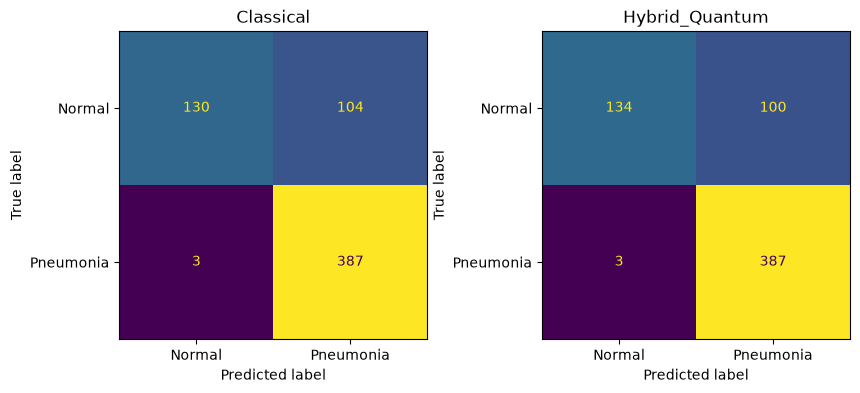

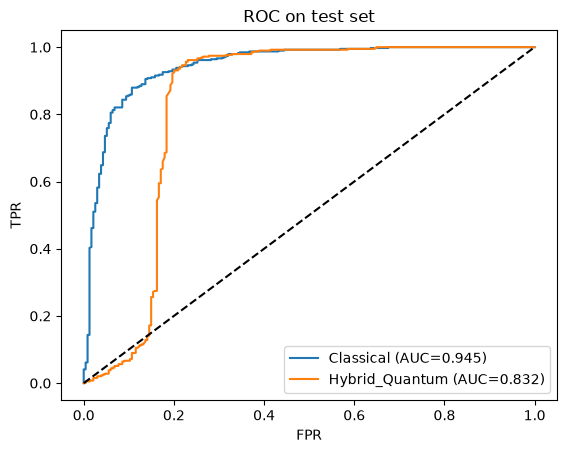

In [9]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, roc_curve, classification_report

import matplotlib.pyplot as plt

def evaluate(model, loader):
    model.eval()
    labels, preds, probs = [], [], []
    with torch.no_grad():
        for x,y in loader:
            out = model(x.to(device)) # shape: (B, 2) -> holds raw scores for each class
            probs.append(torch.softmax(out, 1)[:, 1].cpu()) # performs softmax on raw logits and gets probability score for pneumonia after taking col 1
            preds.append(out.argmax(1).cpu())
            labels.append(y)

    return (torch.cat(labels).numpy(), torch.cat(preds).numpy(), torch.cat(probs).numpy())

results = {}
for name, model in [("Classical", classical_model), ("Hybrid_Quantum", hybrid_model)]:
    y_true, y_pred, y_prob = evaluate(model, test_loader)
    results[name] = (y_true, y_pred, y_prob)
    print(f"\n{name}  |  AUC = {roc_auc_score(y_true, y_prob):.4f}")
    print(classification_report(y_true, y_pred, target_names=["Normal", "Pneumonia"]))

# Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, (yt, yp, _)) in zip(axes, results.items()):
    ConfusionMatrixDisplay(confusion_matrix(yt, yp),
                           display_labels=["Normal", "Pneumonia"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.show()

# ROC curves
for name, (yt, _, yprob) in results.items():
    fpr, tpr, _ = roc_curve(yt, yprob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(yt, yprob):.3f})")
plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("FPR"); plt.ylabel("TPR")
plt.legend(); plt.title("ROC on test set"); plt.show()



        

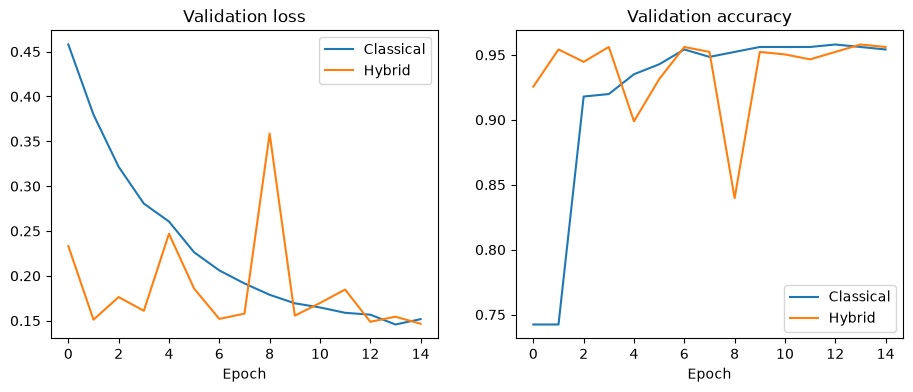

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, h in [("Classical", classical_history), ("Hybrid", quantum_history)]:
    axes[0].plot(h['val_loss'], label=name)
    axes[1].plot(h['val_acc'], label=name)
axes[0].set_title("Validation loss"); axes[1].set_title("Validation accuracy")
for a in axes: a.set_xlabel("Epoch"); a.legend()
plt.show()